<a href="https://colab.research.google.com/github/anupbagale/image-processing-from-scratch/blob/main/notebooks/08_otsu_thresholding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Otsu thresholding

Thresholding splits an image into foreground and background by picking one grey level $t$:
pixels above $t$ become white and the rest become black. Otsu's method picks $t$ automatically by
trying every possible value and keeping the one that best separates the two groups.

"Best separates" means the largest **between-class variance**. If $\omega_0, \omega_1$ are the
fractions of pixels in the two classes and $\mu_0, \mu_1$ their mean grey levels, then

$$\sigma_B^2(t) = \omega_0\,\omega_1\,(\mu_0 - \mu_1)^2$$

Two well-separated groups that are both reasonably large give a high value.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["image.cmap"] = "gray"

The coins image has bright coins on a darker background, which is the kind of image thresholding
is meant for.

In [2]:
image = data.coins()

## Implementation

Everything can be computed from the histogram with cumulative sums. With $N$ pixels, $W(t)$ the
number of pixels with value $\le t$, $M(t)$ the sum of those pixel values and $\mu_T$ the mean of
the whole image, the formula above becomes

$$\sigma_B^2(t) = \frac{\left(\mu_T\,W(t) - M(t)\right)^2}{W(t)\,\big(N - W(t)\big)}$$

up to a constant factor, which does not change where the maximum is. For values of $t$ where one
class is empty the denominator is 0, and those are set to 0.

In [3]:
def otsu_threshold(image):
    histogram = np.bincount(image.ravel(), minlength=256).astype(float)
    total = image.size
    W = np.cumsum(histogram)                       # pixels with value <= t
    M = np.cumsum(histogram * np.arange(256))      # sum of those pixel values
    mu_T = M[-1] / total

    with np.errstate(divide="ignore", invalid="ignore"):
        between = (mu_T * W - M) ** 2 / (W * (total - W))
    between = np.nan_to_num(between)

    t = int(np.argmax(between))
    binary = (image > t).astype(np.uint8) * 255
    return t, binary, between


t, binary, between = otsu_threshold(image)
print("Otsu threshold:", t)

Otsu threshold: 107


Class 0 is defined as the pixels with value $\le t$, so the white class has to be `image > t`.
The first version of this notebook used `image >= t`, which put the pixels with value exactly $t$
into the wrong class.

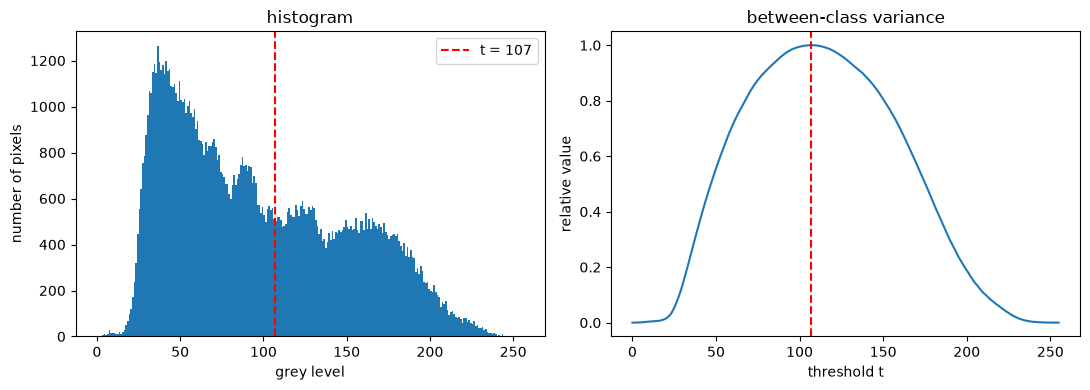

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(image.ravel(), bins=256, range=(0, 256))
ax[0].axvline(t, color="red", ls="--", label=f"t = {t}")
ax[0].set_xlabel("grey level"); ax[0].set_ylabel("number of pixels"); ax[0].set_title("histogram")
ax[0].legend()

ax[1].plot(between / between.max())
ax[1].axvline(t, color="red", ls="--")
ax[1].set_xlabel("threshold t"); ax[1].set_ylabel("relative value")
ax[1].set_title("between-class variance")
plt.tight_layout()
plt.show()

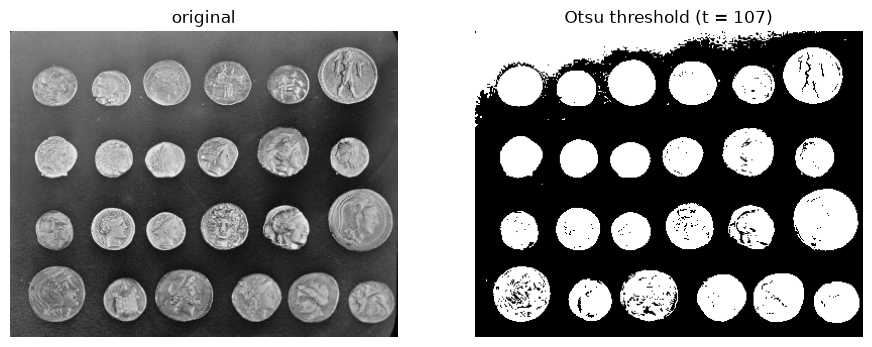

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].imshow(image); ax[0].set_title("original")
ax[1].imshow(binary); ax[1].set_title(f"Otsu threshold (t = {t})")
for a in ax:
    a.axis("off")
plt.show()

The coins are separated from the background, but not perfectly. Some coins have dark areas that
fall below the threshold and show up as black holes, and the background is lighter at the top of
the photo, so part of it ends up white. A single threshold for the whole image cannot handle uneven lighting.
Adaptive (local) thresholding, which picks a different threshold for each region, deals with
this better.

## Comparison with OpenCV

In [6]:
t_cv, binary_cv = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print("OpenCV threshold:", t_cv)
print("same binary image:", np.array_equal(binary, binary_cv))

OpenCV threshold: 107.0
same binary image: True
